In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.metrics import mean_absolute_error, r2_score

from pipeline import build_pipeline

In [7]:
df = pd.read_csv('data/AB_NYC_2019.csv')

valid_rows = df['price'] > 0

X = df.loc[valid_rows].drop(columns = "price")
y = df.loc[valid_rows, "price"]

print("Predictors:", X.shape)
print("Target:", y.shape)


Predictors: (48884, 15)
Target: (48884,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

model = build_pipeline()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("R2:", r2_score(y_test, predictions))

MAE: 70.88807455824129
R2: 0.14872698091817393


In [9]:
model = build_pipeline()

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

mae_scores = -scores

print("Fold MAE:", mae_scores)
print("Average MAE:", mae_scores.mean())
print("MAE Standard Deviation:", mae_scores.std())

Fold MAE: [69.48886697 73.24054854 70.80181211 72.68212889 75.13196555]
Average MAE: 72.2690644124677
MAE Standard Deviation: 1.9592311612943913


In [11]:
unseen_row = X_test.iloc[[0]].copy()

unseen_row["neighbourhood"] = "Unknown New Area"
unseen_row["room_type"] = "Unknown Room Type"
model = build_pipeline()
model.fit(X_train, y_train)
prediction = model.predict(unseen_row)

print("Prediction:", prediction[0])
print("Unseen category test: PASSED")

Prediction: 135.31581581949567
Unseen category test: PASSED


In [12]:
X_missing = X_train.copy()

X_missing["reviews_per_month"] = np.nan

test_model = build_pipeline()

test_model.fit(X_missing, y_train)

test_predictions = test_model.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("All predictions finite:", np.isfinite(test_predictions).all())

Number of predictions: 9777
All predictions finite: True


In [13]:
X_missing = X_train.copy()

X_missing["latitude"] = np.nan

test_model = build_pipeline()

test_model.fit(X_missing, y_train)

predictions = test_model.predict(X_test)

print("Median-imputation test:", np.isfinite(predictions).all())

Median-imputation test: True


In [17]:
# Evaluate the correct pipeline

from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits= 5,
    shuffle=True,
    random_state=42
)

correct_model = build_pipeline()

correct_scores = -cross_val_score(
    correct_model, 
    X_train,
    y_train, 
    cv= cv,
    scoring='neg_mean_absolute_error'
)

print('Correct fold MAE', correct_scores)

print("Correct average MAE", correct_scores.mean())

Correct fold MAE [72.07926878 69.65093733 72.22357365 71.61939573 76.11204555]
Correct average MAE 72.33704421036079


In [18]:
#Deliberately fit preprocessing outside cross-validation

from sklearn.linear_model import Ridge
from pipeline import build_preprocessor

# Deliberately incorrect: preprocessing sees every row
bad_preprocessor = build_preprocessor()

X_leaked = bad_preprocessor.fit_transform(X_train)

# Cross-validate only the regression model
bad_model = Ridge(alpha=10.0)

bad_scores = -cross_val_score(
    bad_model,
    X_leaked,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("Leaked fold MAE:", bad_scores)
print("Leaked average MAE:", bad_scores.mean())

Leaked fold MAE: [71.98419334 69.62623621 72.45749883 71.59266756 75.98765586]
Leaked average MAE: 72.3296503619817


In [19]:
#Calculate the exact difference

import pandas as pd

comparison = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Correct MAE": correct_scores,
    "Leaked MAE": bad_scores
})

comparison["Difference"] = (
    comparison["Leaked MAE"] -
    comparison["Correct MAE"]
)

display(comparison.round(4))

difference = bad_scores.mean() - correct_scores.mean()

print("Difference in average MAE:", round(difference, 6))

if difference < 0:
    print("Leaked preprocessing produced a lower MAE.")
elif difference > 0:
    print("Leaked preprocessing produced a higher MAE.")
else:
    print("Both approaches produced the same average MAE.")

,Fold,Correct MAE,Leaked MAE,Difference
0,1,72.0793,71.9842,-0.0951
1,2,69.6509,69.6262,-0.0247
2,3,72.2236,72.4575,0.2339
3,4,71.6194,71.5927,-0.0267
4,5,76.1120,75.9877,-0.1244


Difference in average MAE: -0.007394
Leaked preprocessing produced a lower MAE.


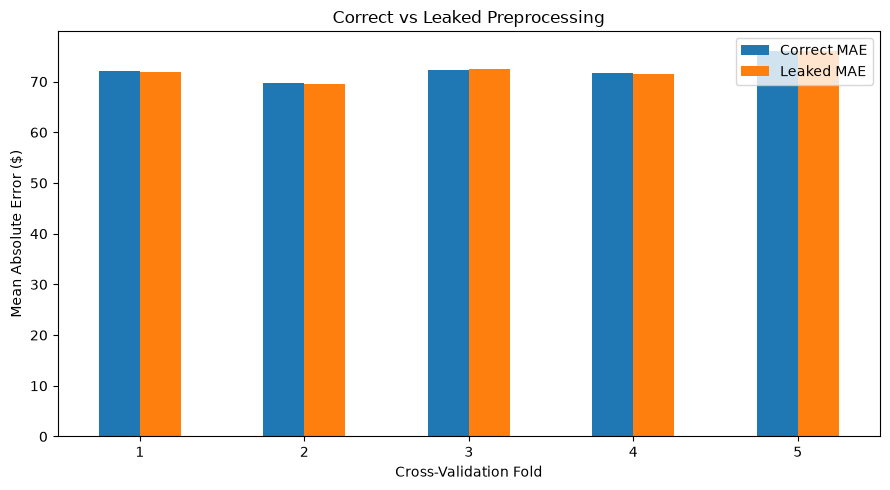

In [20]:
import matplotlib.pyplot as plt

comparison.plot(
    x="Fold",
    y=["Correct MAE", "Leaked MAE"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Correct vs Leaked Preprocessing")
plt.ylabel("Mean Absolute Error ($)")
plt.xlabel("Cross-Validation Fold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
#Experiment 2 — Prove unseen categories are handled correctly

#Build a deliberately fragile encoder

from sklearn.preprocessing import OneHotEncoder

train_categories = pd.DataFrame({
    "room_type": [
        "Private room",
        "Entire home/apt",
        "Shared room"
    ]
})

new_category = pd.DataFrame({
    "room_type": ["Unknown Room Type"]
})

bad_encoder = OneHotEncoder(
    handle_unknown="error"
)

bad_encoder.fit(train_categories)

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent

In [22]:
try:
    bad_encoder.transform(new_category)

except ValueError as error:
    print("Expected error:")
    print(error)

Expected error:
Found unknown categories ['Unknown Room Type'] in column 0 during transform


In [23]:
good_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

good_encoder.fit(train_categories)

result = good_encoder.transform(new_category)

print("Encoded result:", result)
print("Shape:", result.shape)

Encoded result: [[0. 0. 0.]]
Shape: (1, 3)


In [24]:
fitted_preprocessor = model.named_steps["pre"]

feature_names = fitted_preprocessor.get_feature_names_out()

for name in feature_names:
    if "reviews" in name:
        print(name)

print("Total transformed features:", len(feature_names))

log__number_of_reviews
reviews__reviews_per_month
reviews__missingindicator_reviews_per_month
Total transformed features: 105


In [25]:
print("Pipeline steps:")
print(model.named_steps.keys())

print("\nPreprocessing branches:")
print(model.named_steps["pre"].transformers_)

print("\nModel fitted:")
print(hasattr(model.named_steps["model"], "coef_"))

Pipeline steps:
dict_keys(['pre', 'model'])

Preprocessing branches:
[('standard', Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('scaler', StandardScaler())]), ['latitude', 'longitude']), ('log', Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('log',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'log1p'>)),
                ('scaler', StandardScaler())]), ['minimum_nights', 'number_of_reviews']), ('robust', Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('log',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'log1p'>)),
                ('scaler', RobustScaler())]), ['calculated_host_listings_count']), ('availability', Pipeli

In [26]:
#Final reproducibility check
import warnings

from sklearn.model_selection import cross_val_score
from pipeline import build_pipeline

with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")

    scores = cross_val_score(
        build_pipeline(),
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

print("Cross-validation completed:", len(scores) == 5)
print("Warnings found:", len(captured))

for warning in captured:
    print(warning.message)

Cross-validation completed: True
Warnings found: 0
